# 2. Gene selection under nested cross-validation, and a leakage check

The candidate pool of notebook 1 holds far more genes than the development set has deaths, so a survival model needs a short gene list. This notebook compares several ways of choosing that list under one protocol, measures how much a selection made outside the cross-validation inflates the score, and states which method a rule fixed in advance picks. Only the development set is used.

## Settings

The first cell loads the libraries and locates the files. The second names every fold count, seed, threshold and grid, with its reason beside it.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # folds run in parallel processes; one thread each avoids oversubscribing the cores

import hashlib, json, subprocess, sys, time
from importlib.metadata import version
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy import optimize, stats
from sklearn.model_selection import StratifiedKFold
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw
from sksurv.util import Surv

REPO = Path(subprocess.run(["git", "rev-parse", "--show-toplevel"], capture_output=True, text=True, check=True).stdout.strip())
DEVELOPMENT_FILE = REPO / "data" / "processed" / "tcga_development.parquet"  # written by notebook 1; ignored by git
DATA_RESULTS = REPO / "results" / "01_data"
RESULTS = REPO / "results" / "02_gene_selection"  # per-fold results and tables of this notebook; tracked by git
RESULTS.mkdir(parents=True, exist_ok=True)

In [2]:
OUTER_FOLDS, OUTER_SEEDS = 5, [1, 2, 3, 4, 5]  # 5-fold cross-validation repeated 5 times: 25 held-out folds
INNER_FOLDS, INNER_SEED = 5, 0                 # tuning folds inside each training part
EXPRESSED_LOG2, EXPRESSED_SHARE = 1.0, 0.2     # keep a gene with TPM >= 1, that is log2(TPM + 1) >= 1, in at least 20% of training patients
K_GRID = [50, 100, 200, 500]                   # list sizes offered to the two ranking methods
L1_SHARES = [0.25, 0.5, 0.75]                  # elastic-net mixes between pure ridge (0) and pure LASSO (1)
PATH_LENGTH, PATH_DEPTH = 50, 0.01             # 50 penalties from the largest down to 1% of it, the library default
MAX_GENES = 500                                # longest list a penalty path may offer, equal to the largest list size above
RIDGE_GRID = [100.0, 1000.0, 10000.0]          # ridge penalty of the judge: weak, medium and strong shrinkage
CLINICAL_RIDGE = 0.001                         # numerical safeguard on the clinical coefficients, negligible against the data
OPTIMISER = {"gtol": 1e-8, "ftol": 1e-15, "maxiter": 100000, "maxfun": 1000000}  # let the Cox fit run until its gradient is practically zero
GRADIENT_LIMIT = 1e-3                          # largest gradient entry accepted at the end of a Cox fit; the likelihood itself is in the hundreds
DAYS_PER_YEAR = 365.25                         # average length of a year, leap years included
UNO_HORIZON = 5 * DAYS_PER_YEAR                # Uno's C is truncated at 5 years
LEAKAGE_K = 100                                # list size in the leakage contrast and in the negative control
SHUFFLE_SEEDS = [1, 2, 3, 4, 5]                # negative control: five shuffles of the outcomes
STABLE_SHARE = 0.8                             # a gene counts as stable when at least 80% of the lists contain it
CONFIDENCE = 0.95                              # level of every interval
TOP_GENES = 20                                 # most often selected genes shown per method
CHECK_SEED = 0                                 # seed of the small synthetic examples used in the checks
N_JOBS = 4                                     # outer folds evaluated in parallel, one per physical core of the machine used
# Indicator columns of the clinical model; the most common level of each variable is the reference and gets no column.
CLINICAL_LEVELS = {"stage": ["I", "III", "IV", "unknown"], "er": ["negative", "unknown"],
                   "pr": ["negative", "unknown"], "her2": ["positive", "unknown"]}
METHODS = {"M1": {"kind": "clinical only"},
           "M2": {"kind": "variance", "sizes": K_GRID},
           "M3": {"kind": "score test", "sizes": K_GRID},
           "M4": {"kind": "penalised Cox", "l1_shares": [1.0]},
           "M5": {"kind": "penalised Cox", "l1_shares": L1_SHARES}}

## Fixed before running

The protocol below was written down and committed before any model saw a real outcome. The table is rendered from the settings above, so it cannot drift from the code. Harrell's C, the main metric, is the share of comparable patient pairs that a model ranks in the right order: 0.5 is chance and 1 is a perfect ranking. Uno's C is a variant that corrects for censoring.

In [3]:
protocol = {
    "Data": "the development set of notebook 1 only",
    "Outcome": "overall survival as time and event",
    "Primary metric": "Harrell's C on the outer validation folds",
    "Secondary metric": f"Uno's C truncated at {UNO_HORIZON / DAYS_PER_YEAR:.0f} years",
    "Resampling": f"{OUTER_FOLDS} outer folds repeated {len(OUTER_SEEDS)} times (seeds {OUTER_SEEDS[0]} to {OUTER_SEEDS[-1]}), stratified by "
                  f"event; all tuning in {INNER_FOLDS} inner folds of each outer training part",
    "Fitted on training parts only": "expression filter, z-scoring, age median, selection, tuning, the judge",
    "Methods": "M1 clinical covariates only; M2 highest variance; M3 one-gene Cox score test; M4 LASSO-Cox; "
               f"M5 elastic-net Cox with L1 share in {L1_SHARES}; M6 the defended selector (dropped by the compute rule, see below)",
    "Judge": "ridge Cox refit on the listed genes: (a) genes only, primary; (b) genes plus clinical covariates, secondary",
    "Tuning": f"list size in {K_GRID} for M2 and M3; a path of {PATH_LENGTH} penalties for M4 and M5, lists of at most {MAX_GENES} "
              f"genes; ridge penalty of the judge in {RIDGE_GRID}; highest mean inner-fold Harrell's C wins",
    "E-017 hypothesis": f"M5 lists score higher than M4 lists under judge (a); null if the {CONFIDENCE:.0%} interval of the mean "
                        "paired difference includes 0",
    "Interval": "corrected resampled t for repeated cross-validation",
    "Choice rule": "highest mean C under (a); methods whose interval against it includes 0 are tied; among tied methods "
                   "prefer one that uses no outcome, then the higher Jaccard index",
    "E-018 leakage contrast": f"selection on all development patients against selection inside each fold, for M3 at {LEAKAGE_K} genes, M4 and M5",
    "E-019 negative control": f"the same contrast for M3 on {len(SHUFFLE_SEEDS)} shuffles of the outcomes, run first; the clean arm must include 0.50",
    "Compute rule": "8 hours in total; if the projection is over, reduce the repeats from 5 to 3, then drop M6"}
display(Markdown("| Item | Fixed choice |\n|---|---|\n" + "\n".join(f"| {item} | {choice} |" for item, choice in protocol.items())))

| Item | Fixed choice |
|---|---|
| Data | the development set of notebook 1 only |
| Outcome | overall survival as time and event |
| Primary metric | Harrell's C on the outer validation folds |
| Secondary metric | Uno's C truncated at 5 years |
| Resampling | 5 outer folds repeated 5 times (seeds 1 to 5), stratified by event; all tuning in 5 inner folds of each outer training part |
| Fitted on training parts only | expression filter, z-scoring, age median, selection, tuning, the judge |
| Methods | M1 clinical covariates only; M2 highest variance; M3 one-gene Cox score test; M4 LASSO-Cox; M5 elastic-net Cox with L1 share in [0.25, 0.5, 0.75]; M6 the defended selector (dropped by the compute rule, see below) |
| Judge | ridge Cox refit on the listed genes: (a) genes only, primary; (b) genes plus clinical covariates, secondary |
| Tuning | list size in [50, 100, 200, 500] for M2 and M3; a path of 50 penalties for M4 and M5, lists of at most 500 genes; ridge penalty of the judge in [100.0, 1000.0, 10000.0]; highest mean inner-fold Harrell's C wins |
| E-017 hypothesis | M5 lists score higher than M4 lists under judge (a); null if the 95% interval of the mean paired difference includes 0 |
| Interval | corrected resampled t for repeated cross-validation |
| Choice rule | highest mean C under (a); methods whose interval against it includes 0 are tied; among tied methods prefer one that uses no outcome, then the higher Jaccard index |
| E-018 leakage contrast | selection on all development patients against selection inside each fold, for M3 at 100 genes, M4 and M5 |
| E-019 negative control | the same contrast for M3 on 5 shuffles of the outcomes, run first; the clean arm must include 0.50 |
| Compute rule | 8 hours in total; if the projection is over, reduce the repeats from 5 to 3, then drop M6 |

## The development set

We load the development file and compare its checksum with the one notebook 1 recorded, so the experiment provably runs on the locked split. The data are turned into plain arrays: the expression matrix, the outcome, the age, and indicator columns for the clinical levels.

In [4]:
recorded = json.loads((DATA_RESULTS / "split.json").read_text())["tcga_development"]
file_sha256 = hashlib.sha256(DEVELOPMENT_FILE.read_bytes()).hexdigest()
development = pd.read_parquet(DEVELOPMENT_FILE)
gene_ids = [column for column in development.columns if column.startswith("ENSG")]
symbols = pd.read_csv(DATA_RESULTS / "gene_pool.csv").set_index("gene_id")["symbol"]
data = {"expression": development[gene_ids].to_numpy(),
        "time": development["os_days"].to_numpy(dtype=float),
        "event": development["os_event"].to_numpy(dtype=bool),
        "age": development["age"].to_numpy(dtype=float),
        "indicators": np.column_stack([development[name] == level for name, levels in CLINICAL_LEVELS.items()
                                       for level in levels]).astype(float)}
display(Markdown(f"Development set: {len(development)} patients, {data['event'].sum()} deaths, {len(gene_ids)} candidate genes, "
                 f"{data['indicators'].shape[1] + 1} clinical columns."))

Development set: 864 patients, 121 deaths, 19211 candidate genes, 11 clinical columns.

In [5]:
# The experiment is only valid on the split that notebook 1 locked.
assert file_sha256 == recorded["file sha256"], "the development file differs from the one notebook 1 wrote"
assert len(development) == recorded["patients"] and data["event"].sum() == recorded["deaths"], "the cohort counts differ"

## Preparing a fold

Every step that learns from data is fitted on the training part of a fold and then applied to the held-out part: the expression filter, the scaling of each gene to mean 0 and variance 1 (z-scoring), and the median used for a missing age. Using held-out patients in any of these steps is called leakage: the evaluation would then judge a model on patients that helped to build it.

In [6]:
def prepare_fold(data, train, valid):
    """Fit the filter, the scaling and the age fill on the training patients and apply them to both parts."""
    log_train = data["expression"][train]
    mean, sd = log_train.mean(axis=0), log_train.std(axis=0)
    sd[sd == 0] = 1.0  # a constant gene never passes the filter; this only avoids a division by zero
    age = np.where(np.isnan(data["age"]), np.nanmedian(data["age"][train]), data["age"])
    clinical = np.column_stack([(age - age[train].mean()) / age[train].std(), data["indicators"]])
    return {"genes_train": (log_train - mean) / sd, "genes_valid": (data["expression"][valid] - mean) / sd,
            "expressed": np.flatnonzero((log_train >= EXPRESSED_LOG2).mean(axis=0) >= EXPRESSED_SHARE),
            "variance": log_train.var(axis=0),
            "clinical_train": clinical[train], "clinical_valid": clinical[valid],
            "y_train": Surv.from_arrays(data["event"][train], data["time"][train]),
            "y_valid": Surv.from_arrays(data["event"][valid], data["time"][valid])}

In [7]:
# Leakage check: nothing fitted in prepare_fold may depend on the held-out patients, so replacing them by noise must change nothing.
rng = np.random.default_rng(CHECK_SEED)
half = len(data["time"]) // 2
train, valid = np.arange(half), np.arange(half, len(data["time"]))
noisy = {**data, "expression": data["expression"].copy(), "age": data["age"].copy()}
noisy["expression"][valid] = rng.normal(size=(len(valid), len(gene_ids)))
noisy["age"][valid] = rng.normal(size=len(valid))
original, scrambled = prepare_fold(data, train, valid), prepare_fold(noisy, train, valid)
assert all(np.array_equal(original[key], scrambled[key]) for key in ["genes_train", "expressed", "variance", "clinical_train"]), \
    "a step of prepare_fold uses the held-out patients"

## The judge

A gene list is judged by the model it supports. The judge is a Cox regression, the standard model for censored survival times: every patient gets a risk score, a weighted sum of the covariates, and a higher score means a higher hazard, the momentary risk of death. The judge is refit on the listed genes with a ridge penalty, which shrinks all coefficients towards zero, and is scored on patients it has not seen. In variant (b) the clinical covariates join the genes, practically unpenalised. An empty list scores 0.5.

In [8]:
def judge_risk(fold, genes, ridge, with_clinical=False):
    """Refit the ridge Cox model on the listed genes and return its risk score for the held-out patients."""
    train, valid = fold["genes_train"][:, genes], fold["genes_valid"][:, genes]
    penalty = np.full(len(genes), ridge)
    if with_clinical:
        train, valid = np.hstack([fold["clinical_train"], train]), np.hstack([fold["clinical_valid"], valid])
        penalty = np.concatenate([np.full(fold["clinical_train"].shape[1], CLINICAL_RIDGE), penalty])
    if train.shape[1] == 0:
        return np.zeros(len(valid))  # no column at all: every patient gets the same score, which Harrell's C counts as 0.5
    return valid @ fit_ridge_cox(train, fold["y_train"]["time"], fold["y_train"]["event"], penalty)


def harrell_c(fold, risk):
    return concordance_index_censored(fold["y_valid"]["event"], fold["y_valid"]["time"], risk)[0]


def uno_c(fold, risk):
    return concordance_index_ipcw(fold["y_train"], fold["y_valid"], risk, tau=UNO_HORIZON)[0]

The library has the Cox model with a ridge penalty, but its solver needs seconds per fit with hundreds of genes, and the experiment fits the judge many thousands of times. We therefore write down the penalised likelihood of the model and its gradient and let SciPy's optimiser find the coefficients. The assert cell checks on a synthetic example that this fit and the library's give the same coefficients.

In [9]:
def fit_ridge_cox(X, time, event, penalty):
    """Coefficients of a Cox model with one ridge penalty per column (patients with tied times share a risk set)."""
    order = np.argsort(-time, kind="stable")  # longest time first: a running sum is then a sum over the patients still at risk
    X, time, deaths = X[order], time[order], np.flatnonzero(event[order])
    last_at_risk = np.searchsorted(-time, -time, side="right")[deaths] - 1  # last row of the risk set of each death
    death_sum = X[deaths].sum(axis=0)

    def negative_log_likelihood(beta):
        weight = np.exp(X @ beta)
        total = np.cumsum(weight)[last_at_risk]
        weighted = np.cumsum(weight[:, None] * X, axis=0)[last_at_risk]
        value = np.log(total).sum() - death_sum @ beta + 0.5 * penalty @ beta ** 2
        gradient = (weighted / total[:, None]).sum(axis=0) - death_sum + penalty * beta
        return value, gradient

    fit = optimize.minimize(negative_log_likelihood, np.zeros(X.shape[1]), jac=True, method="L-BFGS-B", options=OPTIMISER)
    assert np.abs(negative_log_likelihood(fit.x)[1]).max() < GRADIENT_LIMIT, "the Cox fit stopped before reaching its optimum"
    return fit.x

In [10]:
# The judge's fit must agree with the Cox model of the library.
# Synthetic example: 200 patients, 12 columns, whole-number times so that ties occur, two penalty levels as in variant (b).
rng = np.random.default_rng(CHECK_SEED)
x, t, e = rng.normal(size=(200, 12)), rng.integers(1, 40, size=200).astype(float), rng.random(200) < 0.5
penalty = np.concatenate([np.full(4, CLINICAL_RIDGE), np.full(8, RIDGE_GRID[0])])
library = CoxPHSurvivalAnalysis(alpha=penalty).fit(x, Surv.from_arrays(e, t)).coef_
assert np.allclose(fit_ridge_cox(x, t, e, penalty), library, atol=1e-5), "the judge's fit disagrees with the library's Cox model"

## The selection methods

M2 ranks genes by their variance and uses no outcome. M3 ranks them by a score test: for each gene alone, it asks how strongly expression and hazard go together in a one-gene Cox model. The library has no fast version of this test, so the next cell computes it for all genes at once; the cell after it checks the result against the textbook formula on a small synthetic example.

In [11]:
def cox_score_statistics(Z, time, event):
    """Score test statistic of every column of Z in its own one-gene Cox model (tied times share one risk set)."""
    order = np.argsort(-time, kind="stable")  # longest time first: a running sum is then a sum over the patients still at risk
    Z, time, event = Z[order], time[order], event[order]
    at_risk = np.searchsorted(-time, -time, side="right")[event]  # size of the risk set at each death
    mean = np.cumsum(Z, axis=0)[at_risk - 1] / at_risk[:, None]
    mean_of_squares = np.cumsum(Z ** 2, axis=0)[at_risk - 1] / at_risk[:, None]
    observed_minus_expected = (Z[event] - mean).sum(axis=0)
    return observed_minus_expected / np.sqrt((mean_of_squares - mean ** 2).sum(axis=0))

In [12]:
# The fast score test must agree with the textbook formula computed death by death.
# Synthetic example: 40 patients, 3 genes, whole-number times up to 14 so that ties occur, about half of the patients die.
rng = np.random.default_rng(CHECK_SEED)
z, t, e = rng.normal(size=(40, 3)), rng.integers(1, 15, size=40).astype(float), rng.random(40) < 0.5
slow = np.zeros(3)
spread = np.zeros(3)
for death in np.flatnonzero(e):
    risk_set = z[t >= t[death]]
    slow += z[death] - risk_set.mean(axis=0)
    spread += risk_set.var(axis=0)
assert np.allclose(cox_score_statistics(z, t, e), slow / np.sqrt(spread)), "the fast score test disagrees with the formula"

M4 is LASSO-Cox: a Cox model on all genes with a penalty that sets most coefficients exactly to zero; the genes left with a non-zero coefficient are the list. M5 is the elastic net, which mixes that penalty with a ridge penalty and lets correlated genes enter together. Both are fitted along a path of penalties, and each penalty yields one candidate list.

In [13]:
def candidate_lists(method, fold, settings=None):
    """All gene lists a method offers on one training part, keyed by setting. Inner folds reuse the settings of the outer fit."""
    expressed, y = fold["expressed"], fold["y_train"]
    Z = fold["genes_train"][:, expressed]
    if method["kind"] == "fixed list":
        return {"fixed": np.asarray(method["genes"], dtype=int)}
    if method["kind"] in ("variance", "score test"):
        score = fold["variance"][expressed] if method["kind"] == "variance" else np.abs(cox_score_statistics(Z, y["time"], y["event"]))
        ranking = expressed[np.argsort(-score, kind="stable")]
        return {size: ranking[:size] for size in method["sizes"]}
    lists = {}
    for share in method["l1_shares"]:
        penalties = None if settings is None else [penalty for s, penalty in settings if s == share]
        path = CoxnetSurvivalAnalysis(l1_ratio=share, n_alphas=PATH_LENGTH, alpha_min_ratio=PATH_DEPTH, alphas=penalties).fit(Z, y)
        for column, penalty in enumerate(path.alphas_):
            genes = expressed[np.flatnonzero(path.coef_[:, column])]
            if settings is not None or len(genes) <= MAX_GENES:  # the length limit is applied once, on the outer training part
                lists[(share, float(penalty))] = genes
    return lists

M6, the selector of the defended code (a least-squares LASSO on the class number of the survival time), was part of the plan. Timed on shuffled outcomes before the experiment, its built-in cross-validation alone exceeded the compute limit of this notebook, so the reduction rule fixed in advance drops it.

## Nested cross-validation

Cross-validation holds out one fold of patients, fits on the rest and scores on the held-out fold. In nested cross-validation every choice is itself made by an inner cross-validation that only sees the training part: here the setting of the method and the ridge penalty of the judge. The selection is redone on every inner training part. The held-out fold is used once, to score the list that was chosen without it.

In [14]:
def tune_and_select(method, data, train, outer):
    """Choose the setting of a method and the ridge penalty of the judge on inner folds of the training patients."""
    lists = candidate_lists(method, outer)
    scores = {(setting, ridge): [] for setting in lists for ridge in RIDGE_GRID}
    inner_folds = StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=INNER_SEED).split(train, data["event"][train])
    for inner_train, inner_valid in inner_folds:
        inner = prepare_fold(data, train[inner_train], train[inner_valid])
        inner_lists = candidate_lists(method, inner, settings=list(lists))
        for setting, ridge in scores:
            scores[(setting, ridge)].append(harrell_c(inner, judge_risk(inner, inner_lists[setting], ridge)))
    setting, ridge = max(scores, key=lambda key: np.mean(scores[key]))  # a tie goes to the first entry in grid order
    return lists[setting], ridge, setting


def evaluate_fold(method, data, train, valid):
    """One outer fold: tune on the training patients only, then score the chosen list once on the held-out patients."""
    outer = prepare_fold(data, train, valid)
    if method["kind"] == "clinical only":
        genes, ridge, setting = np.array([], dtype=int), 0.0, "none"
    else:
        genes, ridge, setting = tune_and_select(method, data, train, outer)
    risk, risk_with_clinical = judge_risk(outer, genes, ridge), judge_risk(outer, genes, ridge, with_clinical=True)
    return {"harrell": harrell_c(outer, risk), "uno": uno_c(outer, risk),
            "harrell_with_clinical": harrell_c(outer, risk_with_clinical), "uno_with_clinical": uno_c(outer, risk_with_clinical),
            "genes": [int(gene) for gene in genes], "setting": str(setting), "ridge": ridge}

The outer folds of a run are evaluated in parallel. Every finished run is saved under `results/02_gene_selection/` with the commit that produced it and its running time; a later execution of the notebook reads the saved file, and deleting a file makes the notebook compute it again.

In [15]:
def run_method(method, data, seeds):
    """Evaluate a method on every outer fold of every repeat."""
    folds = [(seed, index, train, valid) for seed in seeds for index, (train, valid) in
             enumerate(StratifiedKFold(OUTER_FOLDS, shuffle=True, random_state=seed).split(data["event"], data["event"]))]
    records = Parallel(n_jobs=N_JOBS)(delayed(evaluate_fold)(method, data, train, valid) for _, _, train, valid in folds)
    return [{"repeat": seed, "fold": index, **record, "genes": [gene_ids[gene] for gene in record["genes"]]}  # lists saved by Ensembl ID
            for (seed, index, _, _), record in zip(folds, records)]


def cached(name, compute):
    """Return the saved result of a run, or compute it, save it and return it."""
    path = RESULTS / f"{name}.json"
    if not path.exists():
        started = time.time()
        result = compute()
        commit = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
        path.write_text(json.dumps({"git commit": commit, "seconds": round(time.time() - started), "result": result}, indent=1))
    return json.loads(path.read_text())["result"]


def selected_on_all(method, data):
    """The leaky way: run the whole selection, tuning included, once on all patients. Returns the list as Ensembl IDs."""
    everyone = np.arange(len(data["time"]))
    return [gene_ids[gene] for gene in tune_and_select(method, data, everyone, prepare_fold(data, everyone, everyone))[0]]


def fixed_list(genes):
    """A method that always offers the given list of Ensembl IDs, so that only the judge is tuned and scored."""
    return {"kind": "fixed list", "genes": pd.Index(gene_ids).get_indexer(genes)}

## E-019: negative control on shuffled outcomes

Before any real outcome is modelled we test the machinery itself. We shuffle the outcomes across patients, which destroys every true link between genes and survival, and run M3 both ways: with selection inside each fold (clean) and with selection on all patients before the cross-validation (leaky). A correct pipeline must score about 0.5 in the clean arm. The leaky arm shows how much score can appear from selection alone.

In [16]:
def negative_control():
    rows = []
    method = {"kind": "score test", "sizes": [LEAKAGE_K]}
    for seed in SHUFFLE_SEEDS:
        order = np.random.default_rng(seed).permutation(len(data["time"]))
        shuffled = {**data, "time": data["time"][order], "event": data["event"][order]}
        for arm, arm_method in [("clean", method), ("leaky", fixed_list(selected_on_all(method, shuffled)))]:
            rows += [{"shuffle": seed, "arm": arm, **record} for record in run_method(arm_method, shuffled, [seed])]
    return rows


def t_interval(values):
    """Mean and t interval of a few independent values."""
    values = np.asarray(values, dtype=float)
    half = stats.t.ppf((1 + CONFIDENCE) / 2, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean(), values.mean() - half, values.mean() + half


control = pd.DataFrame(cached("e019_negative_control", negative_control))
shuffle_means = control.groupby(["arm", "shuffle"])["harrell"].mean().unstack("arm")
control_table = pd.DataFrame({arm: t_interval(shuffle_means[arm]) for arm in ["clean", "leaky"]},
                             index=["mean C", "interval low", "interval high"]).T.round(3)
control_table.to_csv(RESULTS / "e019_table.csv")
control_table

,mean C,interval low,interval high
clean,0.497,0.426,0.569
leaky,0.677,0.597,0.756


In [17]:
# If the clean arm finds signal in shuffled outcomes, the pipeline leaks and no result below could be trusted.
assert control_table.loc["clean", "interval low"] <= 0.5 <= control_table.loc["clean", "interval high"], \
    "the clean arm excludes 0.50 on shuffled outcomes: the code leaks"

## E-017: the methods under one protocol

Each method is now run on the real outcomes of the development set, on the same outer folds. The table gives, per method, the mean and standard deviation of Harrell's C over the folds for the genes alone (a) and for genes plus clinical covariates (b), Uno's C, and the length of the chosen lists. M1 uses no gene, so it has no entry under (a); under (b) it is the clinical model that the other rows must beat. M6 was not run.

In [18]:
runs = {name: pd.DataFrame(cached(f"e017_{name}", lambda method=method: run_method(method, data, OUTER_SEEDS)))
        for name, method in METHODS.items()}


def summarise(folds, has_genes=True):
    lengths = folds["genes"].map(len)
    return {"C genes only (a)": folds["harrell"].mean() if has_genes else np.nan,
            "SD (a)": folds["harrell"].std() if has_genes else np.nan,
            "Uno C (a)": folds["uno"].mean() if has_genes else np.nan,
            "C with clinical (b)": folds["harrell_with_clinical"].mean(), "SD (b)": folds["harrell_with_clinical"].std(),
            "Uno C (b)": folds["uno_with_clinical"].mean(),
            "genes, median": lengths.median(), "genes, range": f"{lengths.min()} to {lengths.max()}"}


results_table = pd.DataFrame.from_dict({name: summarise(folds, has_genes=name != "M1") for name, folds in runs.items()}, orient="index")
results_table.to_csv(RESULTS / "e017_results.csv")
results_table.round(3)

,C genes only (a),SD (a),Uno C (a),C with clinical (b),SD (b),Uno C (b),"genes, median","genes, range"
M1,NaN,NaN,NaN,0.753,0.039,0.713,0.0,0 to 0
M2,0.661,0.052,0.644,0.748,0.043,0.706,500.0,100 to 500
M3,0.681,0.055,0.689,0.748,0.056,0.738,500.0,200 to 500
M4,0.677,0.057,0.682,0.754,0.050,0.741,173.0,2 to 235
M5,0.690,0.061,0.700,0.749,0.058,0.748,292.0,2 to 495


The figure answers one question: how the held-out score of each method spreads over the outer folds under judge (a). Each dot is one fold, the box spans the middle half of the folds with the median as a line, and the dotted line is chance. Compare the spread within a method with the gaps between methods.

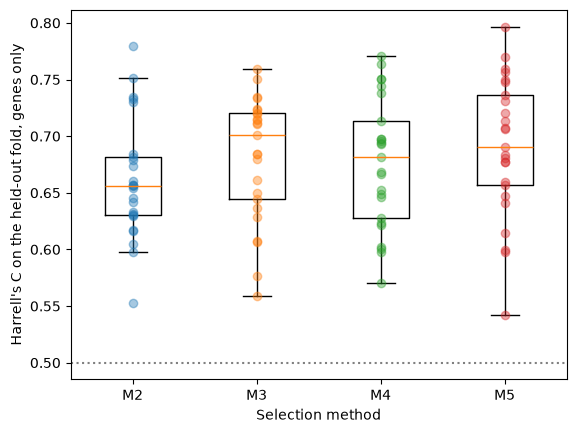

In [19]:
figure, axis = plt.subplots()
gene_methods = [name for name in METHODS if name != "M1"]
axis.boxplot([runs[name]["harrell"] for name in gene_methods], showfliers=False)
for position, name in enumerate(gene_methods, start=1):
    axis.plot(np.full(len(runs[name]), position), runs[name]["harrell"], "o", alpha=0.4)  # see-through dots show overlapping folds
axis.axhline(0.5, linestyle=":", color="grey")  # chance level
axis.set_xticks(range(1, len(gene_methods) + 1), gene_methods)
axis.set_xlabel("Selection method")
axis.set_ylabel("Harrell's C on the held-out fold, genes only")
plt.show()

Two scores from the same fold share the same patients, so methods are compared by their difference on each fold. The training parts of repeated cross-validation overlap, which makes an ordinary t interval too narrow; the corrected resampled t interval widens it to account for the overlap. The registered hypothesis of E-017 is that M5 lists score higher than M4 lists. The result counts as null if the interval includes 0.

In [20]:
def corrected_interval(differences):
    """Mean difference over repeated cross-validation folds with the corrected resampled t interval."""
    differences = np.asarray(differences, dtype=float)
    count = len(differences)
    spread = np.sqrt((1 / count + 1 / (OUTER_FOLDS - 1)) * differences.var(ddof=1))  # 1 / (folds - 1) = test size over training size
    half = stats.t.ppf((1 + CONFIDENCE) / 2, count - 1) * spread
    return differences.mean(), differences.mean() - half, differences.mean() + half


e017_difference, e017_low, e017_high = corrected_interval(runs["M5"]["harrell"] - runs["M4"]["harrell"])
e017_verdict = "includes 0, so the result is null: the elastic net is not shown to beat LASSO here" \
    if e017_low <= 0 <= e017_high else "excludes 0, so the two methods differ"
e017_sentence = (f"M5 minus M4 under judge (a) is {e017_difference:+.3f} on average, {CONFIDENCE:.0%} interval "
                 f"{e017_low:+.3f} to {e017_high:+.3f}; the interval {e017_verdict}")
display(Markdown(f"E-017: {e017_sentence}."))

E-017: M5 minus M4 under judge (a) is +0.014 on average, 95% interval -0.052 to +0.079; the interval includes 0, so the result is null: the elastic net is not shown to beat LASSO here.

A selection method should also return similar lists when the patients change a little. For each method we compare its lists from all outer folds pair by pair with the Jaccard index, the size of the overlap of two lists divided by the size of their union (1 means identical lists, 0 no shared gene). We also count the stable genes, those present in at least the share of lists named `STABLE_SHARE` in the settings.

In [21]:
def jaccard(first, second):
    union = len(set(first) | set(second))
    return len(set(first) & set(second)) / union if union else 1.0  # two empty lists are identical


def stability(folds):
    lists = list(folds["genes"])
    counts = pd.Series([gene for genes in lists for gene in genes]).value_counts()
    return {"mean pairwise Jaccard": np.mean([jaccard(a, b) for a, b in combinations(lists, 2)]),
            "stable genes": int((counts >= STABLE_SHARE * len(lists)).sum())}


stability_table = pd.DataFrame.from_dict({name: stability(runs[name]) for name in gene_methods}, orient="index")
stability_table.to_csv(RESULTS / "e017_stability.csv")
stability_table.round(3)

,mean pairwise Jaccard,stable genes
M2,0.554,101
M3,0.341,144
M4,0.130,7
M5,0.181,23


The table lists the genes that M4 and M5 select most often, each with the number of outer-fold lists that contain it. Genes are shown by symbol.

In [22]:
def most_selected(folds):
    counts = pd.Series([symbols[gene] for genes in folds["genes"] for gene in genes]).value_counts().head(TOP_GENES)
    return [f"{symbol} ({count})" for symbol, count in counts.items()]


top_genes = pd.DataFrame({name: pd.Series(most_selected(runs[name])) for name in ["M4", "M5"]}).fillna("")
top_genes.index = range(1, len(top_genes) + 1)
top_genes.to_csv(RESULTS / "e017_top_genes.csv")
top_genes

,M4,M5
1,CEL (23),CEL (24)
2,SERPINA1 (22),SERPINA1 (24)
3,ASAH2B (21),ST7-AS1 (24)
4,NLRP2 (20),CXorf56 (23)
5,MAP2K6 (20),NLRP2 (23)
6,HSPA2 (20),MAP2K6 (23)
7,ST7-AS1 (20),GNG4 (23)
8,GNG4 (19),CYTL1 (23)
9,CYTL1 (19),ASAH2B (23)
10,MCTS1 (19),HSPA2 (22)


The choice rule was fixed in advance. Take the method with the highest mean C under judge (a). Every method whose corrected interval against it includes 0 is tied with it. Among tied methods prefer one that uses no outcome (only M2), then the one with the higher Jaccard index. The remaining pairwise differences and everything under (b) are exploratory. The rule gives a proposal; adopting it is a separate decision.

In [23]:
mean_c = {name: runs[name]["harrell"].mean() for name in gene_methods}
best = max(mean_c, key=mean_c.get)
against_best = {name: corrected_interval(runs[best]["harrell"] - runs[name]["harrell"]) for name in gene_methods if name != best}
tied = [best] + [name for name, (_, low, high) in against_best.items() if low <= 0 <= high]
chosen = min(tied, key=lambda name: (METHODS[name]["kind"] != "variance", -stability_table.loc[name, "mean pairwise Jaccard"]))
pairwise = pd.DataFrame(against_best, index=["best minus method", "interval low", "interval high"]).T.round(3)
pairwise.to_csv(RESULTS / "e017_against_best.csv")
display(pairwise)
display(Markdown(f"Highest mean C under (a): {best} ({mean_c[best]:.3f}). Tied with it: {', '.join(tied[1:]) or 'no other method'}. "
                 f"The rule picks {chosen}."))

,best minus method,interval low,interval high
M2,0.029,-0.027,0.086
M3,0.009,-0.045,0.063
M4,0.014,-0.052,0.079


Highest mean C under (a): M5 (0.690). Tied with it: M2, M3, M4. The rule picks M2.

Under (b) each list is combined with the clinical covariates and compared with the clinical model alone (M1) on the same folds. These differences are exploratory.

In [24]:
with_clinical = pd.DataFrame({name: corrected_interval(runs[name]["harrell_with_clinical"] - runs["M1"]["harrell_with_clinical"])
                              for name in gene_methods}, index=["method minus M1", "interval low", "interval high"]).T.round(3)
with_clinical.to_csv(RESULTS / "e017_with_clinical.csv")
with_clinical

,method minus M1,interval low,interval high
M2,-0.005,-0.032,0.022
M3,-0.005,-0.060,0.050
M4,0.001,-0.051,0.053
M5,-0.005,-0.054,0.044


## E-018: what selection leakage costs here

The leaky arm runs the selection once on all development patients, tuning included, and then cross-validates only the judge on the same outer folds. The clean arm is the nested result above, where selection happens inside each training part. For M3 both arms use lists of the fixed length `LEAKAGE_K`. The difference, leaky minus clean, is the score that comes from letting the held-out patients take part in the selection.

In [25]:
leak_methods = {"M3": {"kind": "score test", "sizes": [LEAKAGE_K]}, "M4": METHODS["M4"], "M5": METHODS["M5"]}
leak_lists = {name: cached(f"e018_{name}_selected_on_all", lambda method=method: selected_on_all(method, data))
              for name, method in leak_methods.items()}
leaky = {name: pd.DataFrame(cached(f"e018_{name}_leaky", lambda genes=genes: run_method(fixed_list(genes), data, OUTER_SEEDS)))
         for name, genes in leak_lists.items()}
clean = {"M3": pd.DataFrame(cached("e018_M3_clean", lambda: run_method(leak_methods["M3"], data, OUTER_SEEDS))),
         "M4": runs["M4"], "M5": runs["M5"]}
leak_rows = {}
for name in leak_methods:
    difference, low, high = corrected_interval(leaky[name]["harrell"] - clean[name]["harrell"])
    lengths = clean[name]["genes"].map(len)
    leak_rows[name] = {"leaky C": leaky[name]["harrell"].mean(), "clean C": clean[name]["harrell"].mean(),
                       "leaky minus clean": difference, "interval low": low, "interval high": high,
                       "genes, leaky": len(leak_lists[name]), "genes, clean (median)": lengths.median()}
leak_table = pd.DataFrame.from_dict(leak_rows, orient="index")
leak_table.to_csv(RESULTS / "e018_table.csv")
leak_table.round(3)

,leaky C,clean C,leaky minus clean,interval low,interval high,"genes, leaky","genes, clean (median)"
M3,0.765,0.641,0.124,0.070,0.178,100,100.0
M4,0.963,0.677,0.286,0.218,0.354,172,173.0
M5,0.946,0.690,0.255,0.190,0.321,147,292.0


## Questions from the meeting

The four answers below are rendered from the results above.

In [26]:
leak = leak_table["leaky minus clean"]
answers = {
    "S2, why LASSO, why the elastic net, and which is better here":
        f"All methods were compared under one protocol (tables of E-017). For the two penalised methods, {e017_sentence}. "
        f"The rule fixed in advance picks {chosen}; adopting it is a decision for the meeting.",
    "S4, nested cross-validation":
        f"Every tuned quantity (list size, penalty, L1 share, ridge penalty of the judge) is chosen in {INNER_FOLDS} inner folds of "
        f"each training part. Each of the {OUTER_FOLDS * len(OUTER_SEEDS)} outer folds is used once, for scoring only "
        "(block Nested cross-validation).",
    "S5, training, validation and test, and leakage":
        "Notebook 1 locked a test set that no notebook has opened since; this notebook works inside the development set, "
        "whose inner and outer folds play the roles of training and validation. "
        f"On shuffled outcomes the clean pipeline scores {control_table.loc['clean', 'mean C']:.3f} and the leaky one "
        f"{control_table.loc['leaky', 'mean C']:.3f} (E-019). On real outcomes, selecting on all patients changes the score by "
        f"{leak['M3']:+.3f} for M3, {leak['M4']:+.3f} for M4 and {leak['M5']:+.3f} for M5 (table of E-018).",
    "S6, why LASSO was used two times":
        "The defended code ran a least-squares LASSO on the survival class twice: first on all patients, which fixed a gene "
        "universe (`select_features_lasso` in `src/preprocessing.py` on branch `deprecated`), and again inside each fold, within "
        "that universe (`scripts/03b_sage_clinical_lasso_honest.py`). The first step saw the patients that later served as "
        "validation folds. Here selection happens once, inside the training part of each fold, starting from the full candidate "
        "pool (block Nested cross-validation)."}
display(Markdown("\n\n".join(f"{question}. {answer}" for question, answer in answers.items())))

S2, why LASSO, why the elastic net, and which is better here. All methods were compared under one protocol (tables of E-017). For the two penalised methods, M5 minus M4 under judge (a) is +0.014 on average, 95% interval -0.052 to +0.079; the interval includes 0, so the result is null: the elastic net is not shown to beat LASSO here. The rule fixed in advance picks M2; adopting it is a decision for the meeting.

S4, nested cross-validation. Every tuned quantity (list size, penalty, L1 share, ridge penalty of the judge) is chosen in 5 inner folds of each training part. Each of the 25 outer folds is used once, for scoring only (block Nested cross-validation).

S5, training, validation and test, and leakage. Notebook 1 locked a test set that no notebook has opened since; this notebook works inside the development set, whose inner and outer folds play the roles of training and validation. On shuffled outcomes the clean pipeline scores 0.497 and the leaky one 0.677 (E-019). On real outcomes, selecting on all patients changes the score by +0.124 for M3, +0.286 for M4 and +0.255 for M5 (table of E-018).

S6, why LASSO was used two times. The defended code ran a least-squares LASSO on the survival class twice: first on all patients, which fixed a gene universe (`select_features_lasso` in `src/preprocessing.py` on branch `deprecated`), and again inside each fold, within that universe (`scripts/03b_sage_clinical_lasso_honest.py`). The first step saw the patients that later served as validation folds. Here selection happens once, inside the training part of each fold, starting from the full candidate pool (block Nested cross-validation).

## Run record

The last block records the git commit of this execution, the package versions, the seeds, the checksum of the input file, and for each saved run the commit that computed it and its running time.

In [27]:
def git(*arguments):
    return subprocess.run(["git", *arguments], capture_output=True, text=True, check=True).stdout.strip()


saved_runs = {path.stem: {key: json.loads(path.read_text())[key] for key in ["git commit", "seconds"]}
              for path in sorted(RESULTS.glob("e01*.json"))}
run_record = {
    "git commit": git("rev-parse", "HEAD"),
    "tracked files changed since that commit": git("status", "--porcelain", "--untracked-files=no").splitlines(),
    "python": sys.version.split()[0],
    "packages": {name: version(name) for name in ["numpy", "scipy", "pandas", "pyarrow", "scikit-learn", "scikit-survival",
                                                  "joblib", "matplotlib"]},
    "seeds": {"outer folds": OUTER_SEEDS, "inner folds": INNER_SEED, "shuffles": SHUFFLE_SEEDS, "checks": CHECK_SEED},
    "input file (sha256)": {"tcga_development.parquet": file_sha256},
    "saved runs": saved_runs}
(RESULTS / "run_record.json").write_text(json.dumps(run_record, indent=1))
for key, value in run_record.items():
    if key != "saved runs":
        print(f"{key}: {json.dumps(value)}")
pd.DataFrame.from_dict(saved_runs, orient="index")

git commit: "fe72de3902b6122d87542d4d907a0aa35c835f21"
tracked files changed since that commit: []
python: "3.12.14"
packages: {"numpy": "2.5.3", "scipy": "1.18.1", "pandas": "3.0.6", "pyarrow": "25.0.1", "scikit-learn": "1.9.1", "scikit-survival": "0.28.0", "joblib": "1.6.0", "matplotlib": "3.11.2"}
seeds: {"outer folds": [1, 2, 3, 4, 5], "inner folds": 0, "shuffles": [1, 2, 3, 4, 5], "checks": 0}
input file (sha256): {"tcga_development.parquet": "0dd236e52bcbdc4c0a1a17a552158483da3eb3038e054768276e0e4f87d01127"}


,git commit,seconds
e017_M1,fe72de3902b6122d87542d4d907a0aa35c835f21,6
e017_M2,fe72de3902b6122d87542d4d907a0aa35c835f21,62
e017_M3,fe72de3902b6122d87542d4d907a0aa35c835f21,95
e017_M4,fe72de3902b6122d87542d4d907a0aa35c835f21,585
e017_M5,fe72de3902b6122d87542d4d907a0aa35c835f21,1192
e018_M3_clean,fe72de3902b6122d87542d4d907a0aa35c835f21,50
e018_M3_leaky,fe72de3902b6122d87542d4d907a0aa35c835f21,34
e018_M3_selected_on_all,fe72de3902b6122d87542d4d907a0aa35c835f21,3
e018_M4_leaky,fe72de3902b6122d87542d4d907a0aa35c835f21,38
e018_M4_selected_on_all,fe72de3902b6122d87542d4d907a0aa35c835f21,43
